In [1]:
from sklearn.datasets import fetch_california_housing
import pandas as pd

housing = fetch_california_housing(as_frame=True)

df = housing.frame

df.to_csv("california_housing.csv", index=False)

In [3]:
# Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [4]:
# Import Libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

import tensorflow as tf

from tensorflow.keras.models import Sequential

from tensorflow.keras.layers import (
    Dense,
    LeakyReLU,
    ELU
)

from tensorflow.keras.callbacks import EarlyStopping

In [5]:
# Load Dataset
dataset_path = "/content/drive/MyDrive/california_housing.csv"

df = pd.read_csv(dataset_path)

print(df.head())

   MedInc  HouseAge  AveRooms  AveBedrms  Population  AveOccup  Latitude  \
0  8.3252      41.0  6.984127   1.023810       322.0  2.555556     37.88   
1  8.3014      21.0  6.238137   0.971880      2401.0  2.109842     37.86   
2  7.2574      52.0  8.288136   1.073446       496.0  2.802260     37.85   
3  5.6431      52.0  5.817352   1.073059       558.0  2.547945     37.85   
4  3.8462      52.0  6.281853   1.081081       565.0  2.181467     37.85   

   Longitude  MedHouseVal  
0    -122.23        4.526  
1    -122.22        3.585  
2    -122.24        3.521  
3    -122.25        3.413  
4    -122.25        3.422  


In [6]:
# Data Exploration
print(df.shape)

print(df.info())

print(df.describe())

print(df.isnull().sum())

(20640, 9)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB
None
             MedInc      HouseAge      AveRooms     AveBedrms    Population  \
count  20640.000000  20640.000000  20640.000000  20640.000000  20640.000000   
mean       3.870671     28.639486      5.429000      1.096675   1425.476744   
std        1.899822     12.585558      2.474173      0.473911   1132.462122   
min        0.499900      1.000000      0.846154      0.333

In [7]:
# Features and Target
X = df.drop("MedHouseVal", axis=1)

y = df["MedHouseVal"]

In [8]:
# Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [9]:
# Feature Scaling
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)

X_test = scaler.transform(X_test)

In [10]:
# Early Stopping
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=10,
    restore_best_weights=True
)

In [11]:
# ANN Function
def build_model(activation_name, optimizer):

    model = Sequential()

    model.add(Dense(128, input_shape=(8,)))

    if activation_name == "relu":
        model.add(Dense(128, activation='relu'))

    elif activation_name == "leakyrelu":
        model.add(LeakyReLU(alpha=0.1))

    elif activation_name == "elu":
        model.add(ELU(alpha=1.0))


    model.add(Dense(64))

    if activation_name == "relu":
        model.add(tf.keras.layers.Activation('relu'))

    elif activation_name == "leakyrelu":
        model.add(LeakyReLU(alpha=0.1))

    elif activation_name == "elu":
        model.add(ELU(alpha=1.0))


    model.add(Dense(32))

    if activation_name == "relu":
        model.add(tf.keras.layers.Activation('relu'))

    elif activation_name == "leakyrelu":
        model.add(LeakyReLU(alpha=0.1))

    elif activation_name == "elu":
        model.add(ELU(alpha=1.0))


    model.add(Dense(1))

    model.compile(
        optimizer=optimizer,
        loss='mse',
        metrics=['mae']
    )

    return model

In [12]:
# Define Experiments
activations = [
    "relu",
    "leakyrelu",
    "elu"
]

optimizers = [
    "sgd",
    "adam",
    "rmsprop"
]

In [13]:
# Run All Experiments
results = []

histories = {}

for act in activations:

    for opt in optimizers:

        print(f"\nTraining: {act} + {opt}")

        model = build_model(act, opt)

        history = model.fit(
            X_train,
            y_train,
            validation_split=0.2,
            epochs=100,
            batch_size=64,
            callbacks=[early_stop],
            verbose=0
        )

        predictions = model.predict(X_test)

        rmse = np.sqrt(
            mean_squared_error(
                y_test,
                predictions
            )
        )

        results.append(
            [act, opt, rmse]
        )

        histories[f"{act}_{opt}"] = history


Training: relu + sgd


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


129/129 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step

Training: relu + adam


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


129/129 ━━━━━━━━━━━━━━━━━━━━ 0s 798us/step

Training: relu + rmsprop


...

129/129 ━━━━━━━━━━━━━━━━━━━━ 0s 786us/step

Training: elu + adam


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


129/129 ━━━━━━━━━━━━━━━━━━━━ 0s 775us/step

Training: elu + rmsprop


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


129/129 ━━━━━━━━━━━━━━━━━━━━ 0s 779us/step


In [14]:
# Comparison Table
results_df = pd.DataFrame(
    results,
    columns=[
        "Activation",
        "Optimizer",
        "RMSE"
    ]
)

results_df = results_df.sort_values(
    by="RMSE"
)

print(results_df)

  Activation Optimizer      RMSE
0       relu       sgd  0.540937
2       relu   rmsprop  0.650376
1       relu      adam  0.680144
7        elu      adam  0.680212
4  leakyrelu      adam  0.691721
5  leakyrelu   rmsprop  0.713006
6        elu       sgd  0.728404
3  leakyrelu       sgd  0.728782
8        elu   rmsprop  0.751407


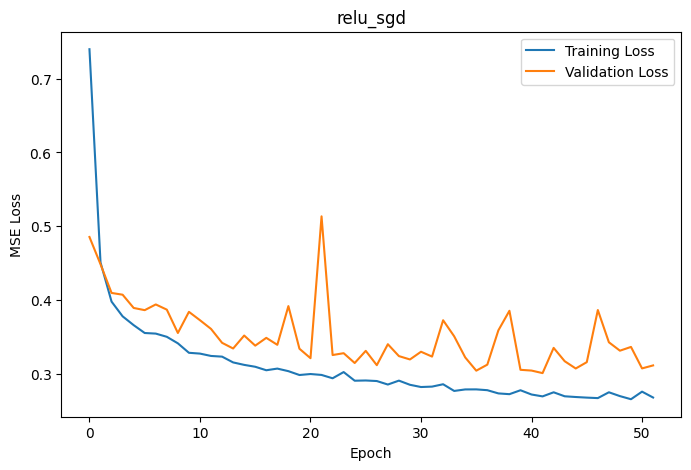

In [15]:
# Learning Curves
best_model = list(histories.keys())[0]

history = histories[best_model]

plt.figure(figsize=(8,5))

plt.plot(history.history['loss'])

plt.plot(history.history['val_loss'])

plt.title(best_model)

plt.xlabel("Epoch")

plt.ylabel("MSE Loss")

plt.legend([
    "Training Loss",
    "Validation Loss"
])

plt.show()

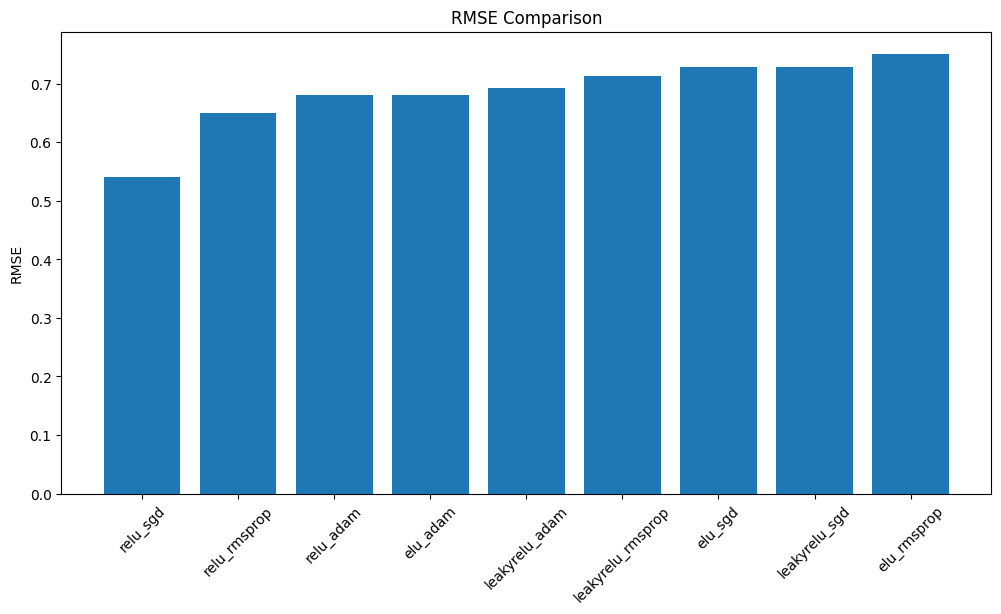

In [16]:
# RMSE Comparison
plt.figure(figsize=(12,6))

labels = results_df["Activation"] + "_" + results_df["Optimizer"]

plt.bar(
    labels,
    results_df["RMSE"]
)

plt.xticks(rotation=45)

plt.ylabel("RMSE")

plt.title("RMSE Comparison")

plt.show()